# Separating Exoplanets from False Positives in Kepler Data
**CMPS 261, Section L2 | Instructor: Aya Kayal**
**Group:** Hasan Jomaa, Mohammad Ammar, Ali Marji
**Repository:** https://github.com/Hasan-jomaa/kepler-exoplanet-classification

This notebook contains the complete pipeline: data cleaning, leakage audit, exploratory analysis,
the model ladder (logistic regression, gradient boosting, neural network), evaluation on a held-out test set,
split sensitivity, calibration, interpretability, complexity analysis, failure analysis with mitigations,
and the final ranking of unresolved candidates.

**Run order:** top to bottom. All randomness is fixed with `RANDOM_STATE = 42`.
In Google Colab, upload `cumulative.csv` (NASA Exoplanet Archive, KOI cumulative table, all columns) to a `data/` folder.

## 0. Setup

In [1]:
# Uncomment in Colab if SHAP is missing
# !pip install -q shap

import os, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import (StratifiedGroupKFold, GridSearchCV, RandomizedSearchCV,
                                     cross_val_predict, learning_curve)
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier, IsolationForest
from sklearn.neural_network import MLPClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_fscore_support,
                             accuracy_score, confusion_matrix, brier_score_loss, precision_recall_curve,
                             roc_curve)
from scipy.stats import loguniform, randint, spearmanr

warnings.filterwarnings("ignore")   # hides repeated MLP convergence / pandas warnings during the searches
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
for d in ["figures", "results", "models", "data"]:
    os.makedirs(d, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
C_PLANET, C_FP = "#2563eb", "#ea580c"
MODEL_COLORS = {"Logistic regression": "#64748b", "Gradient boosting": "#2563eb", "Neural network (MLP)": "#9333ea"}
RESULTS = {}   # every number used in the report is stored here and saved to results/results.json

## 1. Data cleaning and leakage audit
The cleaning reproduces the steps in our progress report (Table 1 there):
1. Load the CSV, skipping NASA's comment lines.
2. Drop objects with no transit model fit (planet radius and SNR both missing). Their missingness reveals the label.
3. Set physically impossible zeros (depth, SNR, insolation, stellar mass) to missing.
4. Engineer 11 features: 8 log transforms, estimated transit count, observed vs. predicted duration, transit vs. catalog stellar density.
5. Keep CONFIRMED (1) and FALSE POSITIVE (0) for training; set CANDIDATE aside for scoring.

In [2]:
TRANSIT = ["koi_period", "koi_duration", "koi_depth", "koi_impact", "koi_model_snr",
           "koi_prad", "koi_ror", "koi_dor", "koi_incl", "koi_sma", "koi_teq",
           "koi_insol", "koi_srho", "koi_count"]
STAR = ["koi_steff", "koi_slogg", "koi_srad", "koi_smass", "koi_smet", "koi_kepmag"]
LOGGED = ["koi_period", "koi_depth", "koi_model_snr", "koi_prad", "koi_insol",
          "koi_ror", "koi_dor", "koi_srad"]
ENGINEERED = ["n_transits_est", "duration_ratio", "log_density_ratio"] + ["log_" + c for c in LOGGED]
CORE = TRANSIT + STAR + ENGINEERED
DIAGNOSTICS = ["koi_num_transits", "koi_max_sngle_ev", "koi_max_mult_ev",
               "koi_bin_oedp_sig", "koi_fwm_stat_sig", "koi_dicco_msky", "koi_dikco_msky"]
LEAKY = ["koi_pdisposition", "koi_score", "koi_fpflag_nt", "koi_fpflag_ss",
         "koi_fpflag_co", "koi_fpflag_ec", "kepler_name", "koi_comment"]
print(len(CORE), "core features |", len(DIAGNOSTICS), "held-back diagnostics |", len(LEAKY), "excluded leaky fields")

raw = pd.read_csv("data/cumulative.csv", comment="#")
print("Raw table:", raw.shape)
print(raw["koi_disposition"].value_counts())

31 core features | 7 held-back diagnostics | 8 excluded leaky fields
Raw table: (9564, 140)
koi_disposition
FALSE POSITIVE    4839
CONFIRMED         2748
CANDIDATE         1977
Name: count, dtype: int64


In [3]:
# Leakage audit: Kepler's own pipeline verdict vs. the final label
resolved = raw[raw["koi_disposition"] != "CANDIDATE"]
agree = (resolved["koi_pdisposition"].replace("CANDIDATE", "CONFIRMED") == resolved["koi_disposition"])
print(pd.crosstab(resolved["koi_pdisposition"], resolved["koi_disposition"]))
print(f"koi_pdisposition agrees with the final label for {agree.sum()} of {len(agree)} resolved objects ({agree.mean():.1%})")
RESULTS["leak_pdisp_agree"] = [int(agree.sum()), int(len(agree))]

# Missing transit fit reveals the label
no_fit = raw["koi_prad"].isna() & raw["koi_model_snr"].isna()
print("\nObjects with no transit fit:", no_fit.sum())
print(raw.loc[no_fit, "koi_disposition"].value_counts())
RESULTS["no_fit"] = raw.loc[no_fit, "koi_disposition"].value_counts().to_dict()

koi_disposition   CONFIRMED  FALSE POSITIVE
koi_pdisposition                           
CANDIDATE              2739               1
FALSE POSITIVE            9            4838
koi_pdisposition agrees with the final label for 7577 of 7587 resolved objects (99.9%)

Objects with no transit fit: 363
koi_disposition
FALSE POSITIVE    257
CANDIDATE         104
CONFIRMED           2
Name: count, dtype: int64


In [4]:
def clean(raw):
    df = raw.copy()
    no_fit = df["koi_prad"].isna() & df["koi_model_snr"].isna()
    df = df[~no_fit].copy()
    for c in ["koi_depth", "koi_model_snr", "koi_insol", "koi_smass"]:
        df.loc[df[c] == 0, c] = np.nan                              # impossible zeros
    df["n_transits_est"] = 1470 / df["koi_period"]                   # ~1,470-day Kepler baseline
    predicted_duration_h = df["koi_period"] * 24 / np.pi / df["koi_dor"]
    df["duration_ratio"] = df["koi_duration"] / predicted_duration_h
    catalog_density = 1.41 * df["koi_smass"] / df["koi_srad"] ** 3  # solar density 1.41 g/cm^3
    df["log_density_ratio"] = np.log10(df["koi_srho"] / catalog_density)
    for c in LOGGED:
        df["log_" + c] = np.log10(df[c])
    df = df.replace([np.inf, -np.inf], np.nan)                       # guard: log10(0) would give -inf
    return df

full = clean(raw)
keep = ["kepid", "kepoi_name"] + CORE + DIAGNOSTICS
labeled_full = full[full["koi_disposition"].isin(["CONFIRMED", "FALSE POSITIVE"])].copy()
labeled_full["label"] = (labeled_full["koi_disposition"] == "CONFIRMED").astype(int)
labeled_full = labeled_full.reset_index(drop=True)
data = labeled_full[keep + ["label"]].copy()
cand_full = full[full["koi_disposition"] == "CANDIDATE"].reset_index(drop=True)
candidates = cand_full[keep].copy()

data.to_csv("data/kepler_clean.csv", index=False)
candidates.to_csv("data/kepler_candidates.csv", index=False)
print("Labeled:", data.shape, "| Candidates:", candidates.shape, "| Host stars:", data["kepid"].nunique())
print(data["label"].value_counts().rename({0: "false positive", 1: "confirmed"}))
print("Missing cells in core features:", int(data[CORE].isna().sum().sum()))
RESULTS.update(n_labeled=len(data), n_candidates=len(candidates), n_stars=int(data["kepid"].nunique()),
               n_confirmed=int(data["label"].sum()), n_fp=int((data["label"] == 0).sum()),
               pos_rate=float(data["label"].mean()), core_missing=int(data[CORE].isna().sum().sum()))

Labeled: (7328, 41) | Candidates: (1873, 40) | Host stars: 6424
label
false positive    4582
confirmed         2746
Name: count, dtype: int64
Missing cells in core features: 26


**Takeaway.** 8 vetting-derived fields are excluded (`koi_pdisposition` alone matches the label 99.9% of the time) and 363 no-fit rows are dropped because their missingness reveals the label. Result: 7,328 labeled objects (37.5% confirmed) on 6,424 stars, 1,873 candidates, 31 core features.

## 2. Exploratory analysis

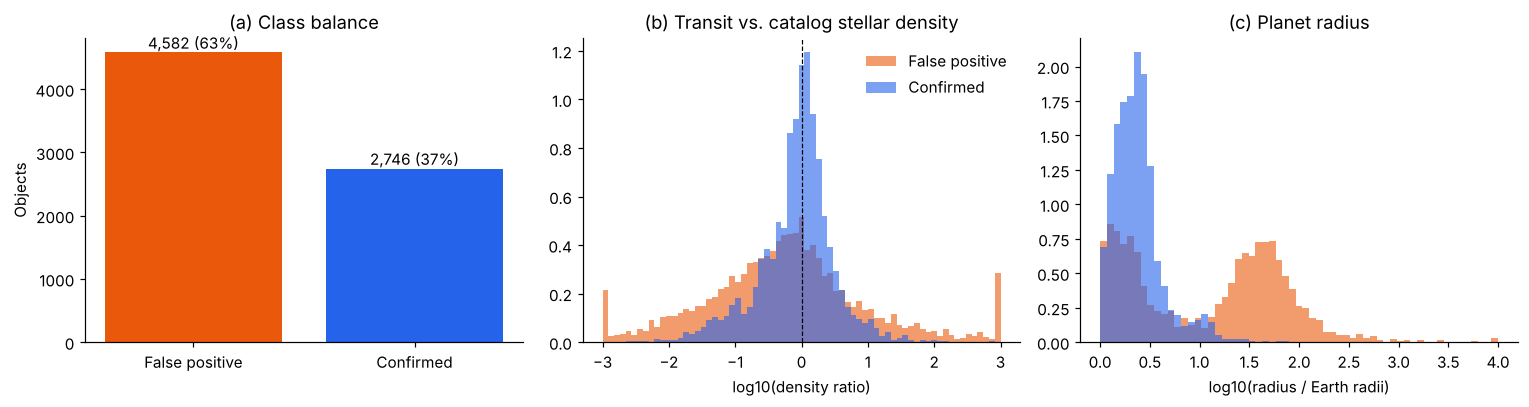

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
counts = data["label"].value_counts().sort_index()
axes[0].bar(["False positive", "Confirmed"], counts.values, color=[C_FP, C_PLANET])
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 60, f"{v:,} ({v/len(data):.0%})", ha="center")
axes[0].set_title("(a) Class balance"); axes[0].set_ylabel("Objects")

bins = np.linspace(-3, 3, 70)
for lab, col, name in [(0, C_FP, "False positive"), (1, C_PLANET, "Confirmed")]:
    axes[1].hist(data.loc[data.label == lab, "log_density_ratio"].clip(-3, 3), bins=bins,
                 alpha=0.6, color=col, label=name, density=True)
axes[1].axvline(0, color="k", lw=0.8, ls="--")
axes[1].set_title("(b) Transit vs. catalog stellar density"); axes[1].set_xlabel("log10(density ratio)")
axes[1].legend(frameon=False)

bins = np.linspace(0, 4, 60)
for lab, col, name in [(0, C_FP, "False positive"), (1, C_PLANET, "Confirmed")]:
    axes[2].hist(data.loc[data.label == lab, "log_koi_prad"].clip(-0.5, 4), bins=bins,
                 alpha=0.6, color=col, label=name, density=True)
axes[2].set_title("(c) Planet radius"); axes[2].set_xlabel("log10(radius / Earth radii)")
plt.tight_layout(); plt.savefig("figures/fig1_eda.png"); plt.show()

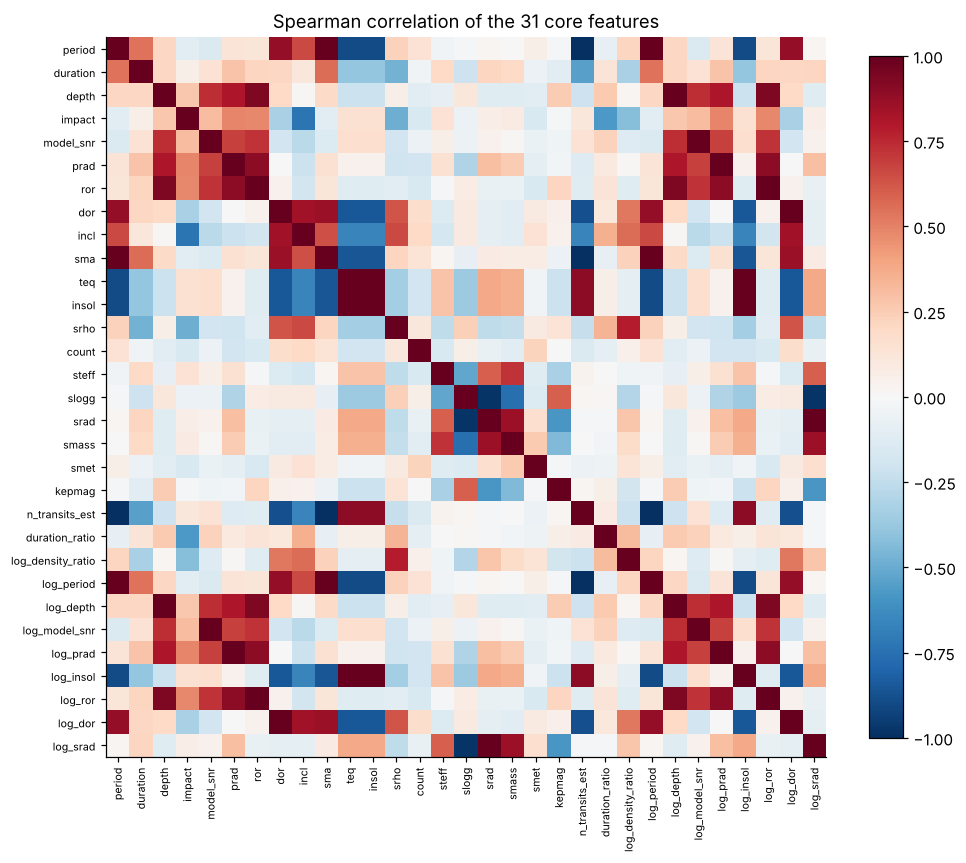

Feature pairs with |rho| > 0.9: 21
                  missing in FP  missing in confirmed
koi_num_transits          0.108                 0.004
koi_max_sngle_ev          0.108                 0.004
koi_max_mult_ev           0.108                 0.004
koi_bin_oedp_sig          0.150                 0.006
koi_fwm_stat_sig          0.162                 0.049
koi_dicco_msky            0.090                 0.004
koi_dikco_msky            0.086                 0.004


In [6]:
# Correlation heatmap of core features (explains why regularization matters for logistic regression)
corr = data[CORE].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(CORE))); ax.set_xticklabels([c.replace("koi_", "") for c in CORE], rotation=90, fontsize=7)
ax.set_yticks(range(len(CORE))); ax.set_yticklabels([c.replace("koi_", "") for c in CORE], fontsize=7)
plt.colorbar(im, fraction=0.04); ax.set_title("Spearman correlation of the 31 core features")
plt.savefig("figures/fig_corr.png"); plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
print("Feature pairs with |rho| > 0.9:", int((pairs.abs() > 0.9).sum()))
RESULTS["n_corr_pairs_09"] = int((pairs.abs() > 0.9).sum())

# Missingness of the held-back diagnostics by class (a hidden-leakage check)
miss = data[DIAGNOSTICS].isna().groupby(data["label"]).mean().T
miss.columns = ["missing in FP", "missing in confirmed"]
print(miss.round(3))
RESULTS["diag_missing_by_class"] = miss.round(4).to_dict()

**Takeaway.** The density ratio and planet radius separate the classes visibly. Many features are strongly correlated (21 pairs with |ρ| > 0.9, mostly raw vs. log versions), which matters for logistic regression. The held-back diagnostics are missing far more often for false positives, a first warning sign of hidden leakage.

## 3. Train/test split
20% of labeled objects are held out **before any tuning**, stratified by class and grouped by host star,
so no star appears in both sets. **No tuning or model choice ever uses the test set**: all tuning uses 5-fold
`StratifiedGroupKFold` on the remaining 80%. Section 6 is the main evaluation. Sections 7, 10 and 13 run
clearly labeled *post-hoc analyses* on the same test set; they explain the model but do not choose it.

In [7]:
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(outer.split(data, data["label"], groups=data["kepid"]))
train, test = data.iloc[train_idx].reset_index(drop=True), data.iloc[test_idx].reset_index(drop=True)
assert set(train.kepid).isdisjoint(test.kepid)
X_tr, y_tr, g_tr = train[CORE], train["label"].values, train["kepid"].values
X_te, y_te = test[CORE], test["label"].values
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print(f"Train: {len(train)} objects ({y_tr.mean():.1%} confirmed) | Test: {len(test)} objects ({y_te.mean():.1%} confirmed)")
RESULTS.update(n_train=len(train), n_test=len(test), test_pos_rate=float(y_te.mean()))

Train: 5861 objects (37.5% confirmed) | Test: 1467 objects (37.5% confirmed)


**Takeaway.** 5,861 training / 1,467 test objects with the same 37.5% positive rate, and no host star on both sides.

## 4. The model ladder
All models are trained on log loss and tuned on PR-AUC (`average_precision`), our primary metric.
* **Level 1a:** Logistic regression, `class_weight="balanced"`, C in {0.01, 0.1, 1, 10, 100} (C = 1/lambda).
* **Level 1b:** Gradient-boosted trees (`HistGradientBoostingClassifier`, handles missing values natively), randomized search.
* **Level 2:** Neural network (multi-layer perceptron), randomized search over architecture, L2 penalty and learning rate, with early stopping.

*Note:* `MLPClassifier` has no `class_weight` option, so the MLP is trained **unweighted**, unlike the other two.
This affects its threshold-0.5 metrics and its calibration before recalibration (Section 9).

In [8]:
def make_lr(C=1.0):
    return Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler()),
                     ("clf", LogisticRegression(C=C, class_weight="balanced", max_iter=5000))])

t0 = time.time()
lr_search = GridSearchCV(make_lr(), {"clf__C": [0.01, 0.1, 1, 10, 100]}, scoring="average_precision",
                         cv=cv, return_train_score=True, n_jobs=-1)
lr_search.fit(X_tr, y_tr, groups=g_tr)
lr_tune_time = time.time() - t0
lr_cv = pd.DataFrame(lr_search.cv_results_)[["param_clf__C", "mean_train_score", "mean_test_score", "std_test_score"]]
print(lr_cv.round(4))
print("Best C:", lr_search.best_params_["clf__C"], "| CV PR-AUC:", round(lr_search.best_score_, 4))
RESULTS["lr_grid"] = lr_cv.round(4).astype(float).values.tolist()

   param_clf__C  mean_train_score  mean_test_score  std_test_score
0          0.01            0.9104           0.9105          0.0093
1          0.10            0.9320           0.9309          0.0091
2          1.00            0.9407           0.9384          0.0088
3         10.00            0.9447           0.9420          0.0083
4        100.00            0.9462           0.9420          0.0094
Best C: 10 | CV PR-AUC: 0.942


In [9]:
hgb_space = {"learning_rate": loguniform(0.01, 0.3), "max_depth": [3, 4, 6, 8, None],
             "max_iter": randint(100, 500), "min_samples_leaf": randint(10, 100),
             "l2_regularization": loguniform(1e-3, 10), "max_leaf_nodes": randint(15, 63)}
t0 = time.time()
hgb_search = RandomizedSearchCV(HistGradientBoostingClassifier(random_state=RANDOM_STATE, class_weight="balanced"),
                                hgb_space, n_iter=25, scoring="average_precision", cv=cv,
                                random_state=RANDOM_STATE, n_jobs=-1, return_train_score=True)
hgb_search.fit(X_tr, y_tr, groups=g_tr)
hgb_tune_time = time.time() - t0
print("Best params:", hgb_search.best_params_)
print("CV PR-AUC:", round(hgb_search.best_score_, 4),
      "| train PR-AUC:", round(hgb_search.cv_results_["mean_train_score"][hgb_search.best_index_], 4))

Best params: {'l2_regularization': np.float64(1.8274508859816028), 'learning_rate': np.float64(0.11069143219393454), 'max_depth': 6, 'max_iter': 388, 'max_leaf_nodes': 19, 'min_samples_leaf': 50}
CV PR-AUC: 0.9701 | train PR-AUC: 1.0


In [10]:
def make_mlp(**kw):
    return Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler()),
                     ("clf", MLPClassifier(early_stopping=True, validation_fraction=0.15, n_iter_no_change=20,
                                           max_iter=1000, random_state=RANDOM_STATE, **kw))])

mlp_space = {"clf__hidden_layer_sizes": [(32,), (64,), (128,), (64, 32), (128, 64), (128, 64, 32), (256, 128)],
             "clf__alpha": loguniform(1e-5, 1e-1), "clf__learning_rate_init": loguniform(1e-4, 1e-2),
             "clf__batch_size": [64, 128, 256], "clf__activation": ["relu", "tanh"]}
t0 = time.time()
mlp_search = RandomizedSearchCV(make_mlp(), mlp_space, n_iter=25, scoring="average_precision", cv=cv,
                                random_state=RANDOM_STATE, n_jobs=-1, return_train_score=True)
mlp_search.fit(X_tr, y_tr, groups=g_tr)
mlp_tune_time = time.time() - t0
print("Best params:", mlp_search.best_params_)
print("CV PR-AUC:", round(mlp_search.best_score_, 4),
      "| train PR-AUC:", round(mlp_search.cv_results_["mean_train_score"][mlp_search.best_index_], 4))

Best params: {'clf__activation': 'relu', 'clf__alpha': np.float64(0.027527173929429397), 'clf__batch_size': 256, 'clf__hidden_layer_sizes': (128, 64), 'clf__learning_rate_init': np.float64(0.0007961566078062948)}
CV PR-AUC: 0.9668 | train PR-AUC: 0.9781


In [11]:
best = {"Logistic regression": lr_search.best_estimator_,
        "Gradient boosting": hgb_search.best_estimator_,
        "Neural network (MLP)": mlp_search.best_estimator_}
searches = {"Logistic regression": lr_search, "Gradient boosting": hgb_search, "Neural network (MLP)": mlp_search}
RESULTS["cv"] = {k: {"cv_prauc": float(s.best_score_),
                     "cv_prauc_std": float(s.cv_results_["std_test_score"][s.best_index_]),
                     "train_prauc": float(s.cv_results_["mean_train_score"][s.best_index_])}
                 for k, s in searches.items()}
RESULTS["best_params"] = {k: {p: (v if isinstance(v, (int, float, str, type(None))) else str(v))
                              for p, v in s.best_params_.items()} for k, s in searches.items()}
RESULTS["tune_time_s"] = {"Logistic regression": lr_tune_time, "Gradient boosting": hgb_tune_time,
                          "Neural network (MLP)": mlp_tune_time}
pd.DataFrame(RESULTS["cv"]).T.round(4)

,cv_prauc,cv_prauc_std,train_prauc
Logistic regression,0.9420,0.0083,0.9447
Gradient boosting,0.9701,0.0079,1.0000
Neural network (MLP),0.9668,0.0076,0.9781


**Takeaway.** Cross-validated PR-AUC: boosting 0.970 > MLP 0.967 > logistic regression 0.942. Boosting fits the training folds perfectly (1.000), so it has the most variance, but it still validates best.

## 5. Learning curves (bias vs. variance)

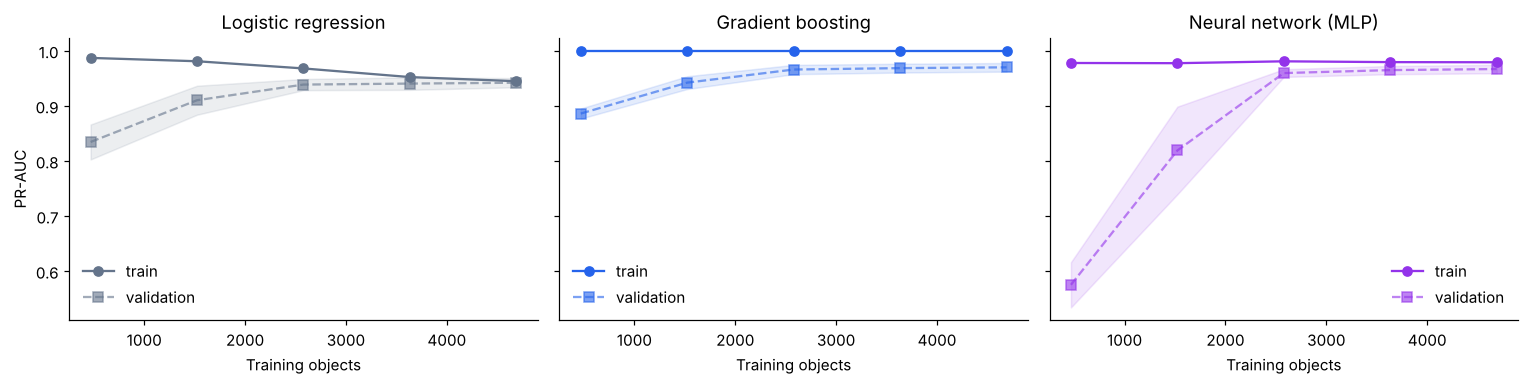

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
RESULTS["learning_curve"] = {}
for ax, (name, est) in zip(axes, best.items()):
    sizes, tr_s, va_s = learning_curve(est, X_tr, y_tr, groups=g_tr, cv=cv, scoring="average_precision",
                                       train_sizes=np.linspace(0.1, 1.0, 5), n_jobs=-1)
    ax.plot(sizes, tr_s.mean(1), "o-", color=MODEL_COLORS[name], label="train")
    ax.plot(sizes, va_s.mean(1), "s--", color=MODEL_COLORS[name], alpha=0.6, label="validation")
    ax.fill_between(sizes, va_s.mean(1) - va_s.std(1), va_s.mean(1) + va_s.std(1), color=MODEL_COLORS[name], alpha=0.12)
    ax.set_title(name); ax.set_xlabel("Training objects"); ax.legend(frameon=False)
    RESULTS["learning_curve"][name] = {"sizes": sizes.tolist(), "train": tr_s.mean(1).round(4).tolist(),
                                       "val": va_s.mean(1).round(4).tolist()}
axes[0].set_ylabel("PR-AUC")
plt.tight_layout(); plt.savefig("figures/fig_learning_curves.png"); plt.show()

**Takeaway.** Logistic regression: train ≈ validation (high bias). Boosting: large train/validation gap, validation close to a plateau. MLP: poor with little data (0.58 at ~470 objects), catching up only above ~2,500.

## 6. Held-out test evaluation (main result)
All modeling choices are fixed at this point. Each tuned model is refit on the full 80% training set and evaluated on the untouched 20% test set.
Threshold = 0.5 for precision, recall, F1 and accuracy.

In [13]:
def metrics(y, p, thr=0.5):
    pred = (p >= thr).astype(int)
    pr, rc, f1, _ = precision_recall_fscore_support(y, pred, average="binary", zero_division=0)
    return {"PR-AUC": average_precision_score(y, p), "ROC-AUC": roc_auc_score(y, p), "Precision": pr,
            "Recall": rc, "F1": f1, "Accuracy": accuracy_score(y, pred), "Brier": brier_score_loss(y, p)}

test_probs, fit_time, pred_time = {}, {}, {}
for name, est in best.items():
    t0 = time.time(); est.fit(X_tr, y_tr); fit_time[name] = time.time() - t0
    t0 = time.time()
    for _ in range(20): p = est.predict_proba(X_te)[:, 1]
    pred_time[name] = (time.time() - t0) / 20 / len(X_te) * 1e6     # milliseconds per 1,000 objects
    test_probs[name] = p
test_table = pd.DataFrame({n: metrics(y_te, p) for n, p in test_probs.items()}).T
RESULTS["test"] = test_table.round(4).to_dict(orient="index")
test_table.round(3)

,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy,Brier
Logistic regression,0.950,0.971,0.841,0.933,0.884,0.909,0.066
Gradient boosting,0.975,0.987,0.921,0.958,0.939,0.954,0.040
Neural network (MLP),0.963,0.981,0.905,0.920,0.913,0.934,0.048


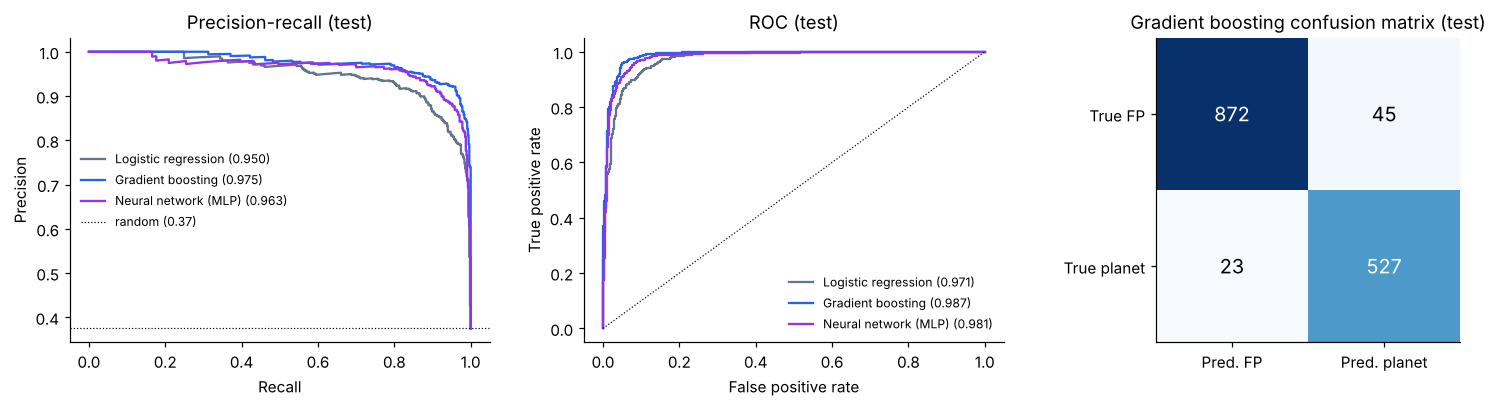

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for name, p in test_probs.items():
    pr, rc, _ = precision_recall_curve(y_te, p)
    axes[0].plot(rc, pr, color=MODEL_COLORS[name], label=f"{name} ({average_precision_score(y_te, p):.3f})")
    fpr, tpr, _ = roc_curve(y_te, p)
    axes[1].plot(fpr, tpr, color=MODEL_COLORS[name], label=f"{name} ({roc_auc_score(y_te, p):.3f})")
axes[0].axhline(y_te.mean(), color="k", ls=":", lw=0.8, label=f"random ({y_te.mean():.2f})")
axes[0].set_xlabel("Recall"); axes[0].set_ylabel("Precision"); axes[0].set_title("Precision-recall (test)")
axes[0].legend(frameon=False, fontsize=8)
axes[1].plot([0, 1], [0, 1], "k:", lw=0.8); axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate")
axes[1].set_title("ROC (test)"); axes[1].legend(frameon=False, fontsize=8)
cm = confusion_matrix(y_te, (test_probs["Gradient boosting"] >= 0.5).astype(int))
axes[2].imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    axes[2].text(j, i, v, ha="center", va="center", color="white" if v > cm.max() / 2 else "black", fontsize=13)
axes[2].set_xticks([0, 1]); axes[2].set_xticklabels(["Pred. FP", "Pred. planet"])
axes[2].set_yticks([0, 1]); axes[2].set_yticklabels(["True FP", "True planet"])
axes[2].set_title("Gradient boosting confusion matrix (test)")
plt.tight_layout(); plt.savefig("figures/fig_test_curves.png"); plt.show()
RESULTS["cm_hgb"] = cm.tolist()

**Takeaway.** On the held-out test set boosting is best on every metric (PR-AUC 0.975 vs. 0.950 for logistic regression) and halves the false alarms (97 → 45) while missing fewer planets (37 → 23).

## 7. Leakage experiment: what the "existing system" fields add
*Post-hoc analysis on the test set: these results are not used to choose the main model.*

Using the tuned gradient-boosting configuration, we compare four feature sets on the same split:
core (31), core + held-back pipeline diagnostics (38), core + Kepler vetting outputs (`koi_score`,
`koi_pdisposition`, four `koi_fpflag_*` flags), and `koi_score` alone (Kepler's own ranking).

In [15]:
lab_tr, lab_te = labeled_full.iloc[train_idx].reset_index(drop=True), labeled_full.iloc[test_idx].reset_index(drop=True)
LEAK_NUM = ["koi_score", "koi_fpflag_nt", "koi_fpflag_ss", "koi_fpflag_co", "koi_fpflag_ec"]
for df_ in (lab_tr, lab_te):
    df_["pdisp_is_candidate"] = (df_["koi_pdisposition"] == "CANDIDATE").astype(int)
feature_sets = {"Core (31)": CORE, "+ pipeline diagnostics (38)": CORE + DIAGNOSTICS,
                "+ Kepler vetting outputs (leaky)": CORE + LEAK_NUM + ["pdisp_is_candidate"]}
hgb_params = hgb_search.best_estimator_.get_params()
leak_rows = {}
for name, cols in feature_sets.items():
    m = HistGradientBoostingClassifier(**hgb_params).fit(lab_tr[cols], y_tr)
    leak_rows[name] = metrics(y_te, m.predict_proba(lab_te[cols])[:, 1])
score = lab_te["koi_score"].fillna(0).values
leak_rows["koi_score alone (existing system)"] = metrics(y_te, score)
leak_table = pd.DataFrame(leak_rows).T
RESULTS["leakage"] = leak_table.round(4).to_dict(orient="index")
leak_table.round(3)

,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy,Brier
Core (31),0.975,0.987,0.921,0.958,0.939,0.954,0.040
+ pipeline diagnostics (38),0.997,0.998,0.975,0.975,0.975,0.981,0.015
+ Kepler vetting outputs (leaky),0.997,0.999,0.998,0.998,0.998,0.999,0.001
koi_score alone (existing system),0.975,0.986,0.971,0.958,0.964,0.973,0.024


In [16]:
# Why do the "held-back diagnostics" help so much? Univariate check and links to the vetting flags
diag_check = []
for c in DIAGNOSTICS:
    v = lab_tr[c]
    auc = roc_auc_score(y_tr[v.notna()], v[v.notna()])
    diag_check.append({"feature": c, "univariate ROC-AUC": max(auc, 1 - auc),
                       "missing %": v.isna().mean() * 100,
                       "corr with fpflag_co": spearmanr(v, lab_tr["koi_fpflag_co"], nan_policy="omit")[0],
                       "corr with fpflag_ss": spearmanr(v, lab_tr["koi_fpflag_ss"], nan_policy="omit")[0]})
diag_check = pd.DataFrame(diag_check).set_index("feature")
RESULTS["diag_check"] = diag_check.round(3).to_dict(orient="index")
diag_check.round(3)

,univariate ROC-AUC,missing %,corr with fpflag_co,corr with fpflag_ss
feature,,,,
koi_num_transits,0.620,6.927,0.338,0.034
koi_max_sngle_ev,0.607,6.927,-0.271,0.523
koi_max_mult_ev,0.525,6.927,-0.253,0.533
koi_bin_oedp_sig,0.567,9.794,0.198,-0.217
koi_fwm_stat_sig,0.766,12.012,-0.439,-0.430
koi_dicco_msky,0.699,5.886,0.635,-0.119
koi_dikco_msky,0.689,5.579,0.667,-0.151


**Takeaway.** Vetting outputs give ~99.9% accuracy by copying the answer, so they stay out. Our core model ranks as well as Kepler's own `koi_score` (0.975 vs. 0.975). The pipeline diagnostics push PR-AUC to 0.997; the centroid measures correlate 0.64–0.67 with the centroid vetting flag because the vetting rules threshold them, so they are held back from the main model.

## 8. Split sensitivity
Are the conclusions stable if the test split changes? We re-split the data with 5 different seeds
(grouped, stratified 80/20), refit each model with its tuned hyperparameters, and report mean and spread.

In [17]:
rows = []
for seed in range(5):
    sp = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=100 + seed)
    tr_i, te_i = next(sp.split(data, data["label"], groups=data["kepid"]))
    for name, est in best.items():
        e = clone(est).fit(data.iloc[tr_i][CORE], data.iloc[tr_i]["label"])
        p = e.predict_proba(data.iloc[te_i][CORE])[:, 1]
        r = metrics(data.iloc[te_i]["label"].values, p); r.update(model=name, seed=seed); rows.append(r)
sens = pd.DataFrame(rows)
sens_summary = sens.groupby("model")[["PR-AUC", "ROC-AUC", "F1"]].agg(["mean", "std", "min", "max"])
wins = sens.pivot(index="seed", columns="model", values="PR-AUC")
print("Best model by PR-AUC on each split:", wins.idxmax(axis=1).tolist())
RESULTS["sensitivity"] = {m: {"PR-AUC mean": float(sens_summary.loc[m, ("PR-AUC", "mean")]),
                              "PR-AUC std": float(sens_summary.loc[m, ("PR-AUC", "std")]),
                              "PR-AUC min": float(sens_summary.loc[m, ("PR-AUC", "min")]),
                              "PR-AUC max": float(sens_summary.loc[m, ("PR-AUC", "max")]),
                              "F1 mean": float(sens_summary.loc[m, ("F1", "mean")]),
                              "F1 std": float(sens_summary.loc[m, ("F1", "std")])} for m in sens_summary.index}
RESULTS["sens_wins"] = wins.idxmax(axis=1).tolist()
RESULTS["sens_hgb_minus_mlp"] = (wins["Gradient boosting"] - wins["Neural network (MLP)"]).round(4).tolist()
sens_summary.round(4)

Best model by PR-AUC on each split: ['Gradient boosting', 'Gradient boosting', 'Gradient boosting', 'Gradient boosting', 'Gradient boosting']


PR-AUC                         ROC-AUC                  \
                        mean     std     min     max    mean     std     min   
model                                                                          
Gradient boosting     0.9707  0.0060  0.9641  0.9768  0.9829  0.0025  0.9809   
Logistic regression   0.9440  0.0100  0.9296  0.9545  0.9680  0.0035  0.9637   
Neural network (MLP)  0.9653  0.0079  0.9566  0.9747  0.9804  0.0024  0.9769   

                                  F1                          
                         max    mean     std     min     max  
model                                                         
Gradient boosting     0.9867  0.9235  0.0035  0.9179  0.9273  
Logistic regression   0.9723  0.8781  0.0058  0.8695  0.8833  
Neural network (MLP)  0.9829  0.9153  0.0062  0.9066  0.9231

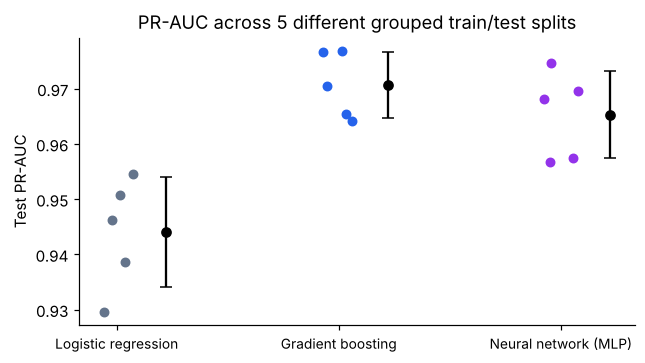

In [18]:
fig, ax = plt.subplots(figsize=(6, 3.4))
for i, name in enumerate(best):
    v = sens.loc[sens.model == name, "PR-AUC"]
    ax.scatter(np.full(len(v), i) + np.random.uniform(-0.08, 0.08, len(v)), v, color=MODEL_COLORS[name], s=30)
    ax.errorbar(i + 0.22, v.mean(), yerr=v.std(), fmt="o", color="k", capsize=4)
ax.set_xticks(range(3)); ax.set_xticklabels(list(best), fontsize=9); ax.set_ylabel("Test PR-AUC")
ax.set_title("PR-AUC across 5 different grouped train/test splits")
plt.tight_layout(); plt.savefig("figures/fig_sensitivity.png"); plt.show()

**Takeaway.** Boosting wins on all 5 alternative splits. Its margin over logistic regression (~0.027) is about four times the split-to-split spread; its margin over the MLP (0.002–0.009) is consistent but small. *Limitation:* hyperparameters were tuned on the original split, so the new test splits partly overlap with the tuning data, which is mildly optimistic.

## 9. Can the model's confidence be trusted? (calibration)
Reliability diagrams on the test set, Brier score and expected calibration error (ECE, 10 bins).
Because `class_weight="balanced"` deliberately shifts probabilities, we also test a mitigation:
isotonic recalibration learned from **out-of-fold** predictions on the training set (no test data used).

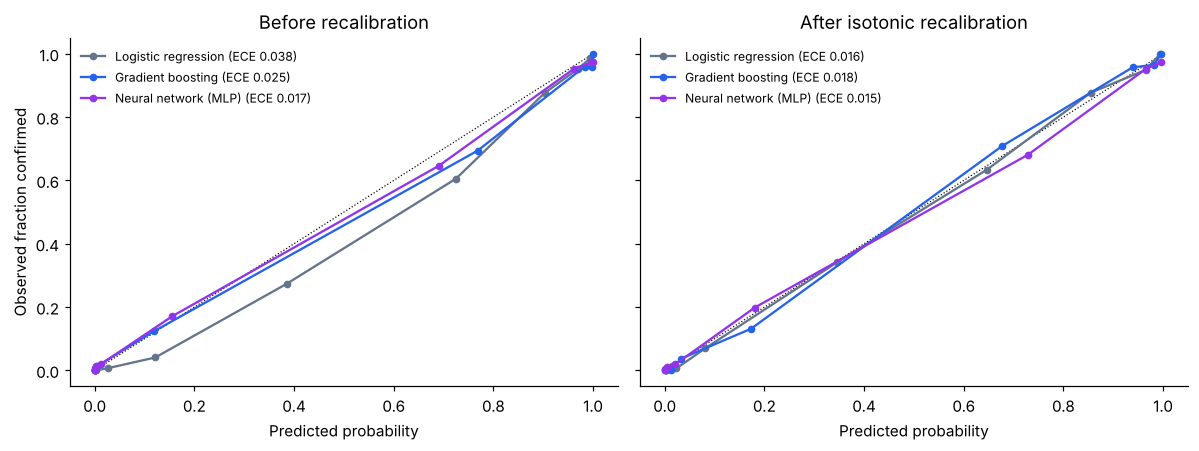

ECE   Brier
Logistic regression  Before recalibration          0.0378  0.0662
                     After isotonic recalibration  0.0160  0.0631
Gradient boosting    Before recalibration          0.0248  0.0398
                     After isotonic recalibration  0.0178  0.0400
Neural network (MLP) Before recalibration          0.0168  0.0478
                     After isotonic recalibration  0.0151  0.0484

In [19]:
def ece(y, p, bins=10):
    edges = np.linspace(0, 1, bins + 1); idx = np.clip(np.digitize(p, edges) - 1, 0, bins - 1)
    return sum(abs(y[idx == b].mean() - p[idx == b].mean()) * (idx == b).mean() for b in range(bins) if (idx == b).any())

oof = {name: cross_val_predict(clone(est), X_tr, y_tr, groups=g_tr, cv=cv,
                               method="predict_proba", n_jobs=-1)[:, 1] for name, est in best.items()}
calibrators = {name: IsotonicRegression(out_of_bounds="clip").fit(oof[name], y_tr) for name in best}
cal_probs = {name: calibrators[name].predict(test_probs[name]) for name in best}

cal_rows = {}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, (title, probs) in zip(axes, [("Before recalibration", test_probs), ("After isotonic recalibration", cal_probs)]):
    ax.plot([0, 1], [0, 1], "k:", lw=0.8)
    for name, p in probs.items():
        fr, mp = calibration_curve(y_te, p, n_bins=10, strategy="quantile")
        ax.plot(mp, fr, "o-", color=MODEL_COLORS[name], label=f"{name} (ECE {ece(y_te, p):.3f})", ms=4)
        cal_rows.setdefault(name, {})[title] = {"ECE": ece(y_te, p), "Brier": brier_score_loss(y_te, p)}
    ax.set_title(title); ax.set_xlabel("Predicted probability"); ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel("Observed fraction confirmed")
plt.tight_layout(); plt.savefig("figures/fig_calibration.png"); plt.show()
RESULTS["calibration"] = cal_rows
pd.DataFrame({(n, t): v for n, d in cal_rows.items() for t, v in d.items()}).T.round(4)

**Takeaway.** Before recalibration ECE is 0.038 (LR), 0.025 (boosting), 0.017 (MLP). LR is worst because balanced class weights push probabilities up; the MLP's good raw calibration is partly because it is trained unweighted. Isotonic recalibration on out-of-fold predictions brings all three to ~0.015–0.018.

## 10. Interpretability
*Permutation importance and SHAP are computed on the test set as post-hoc explanations of the already-chosen model.*

Top logistic regression coefficients:
koi_depth           -15.647
koi_impact           -7.802
koi_ror              -3.980
log_koi_model_snr     3.173
log_koi_period        2.821
koi_dor              -2.811
log_koi_insol         2.488
koi_sma              -2.172
log_koi_dor           2.114
koi_duration         -1.661
dtype: float64


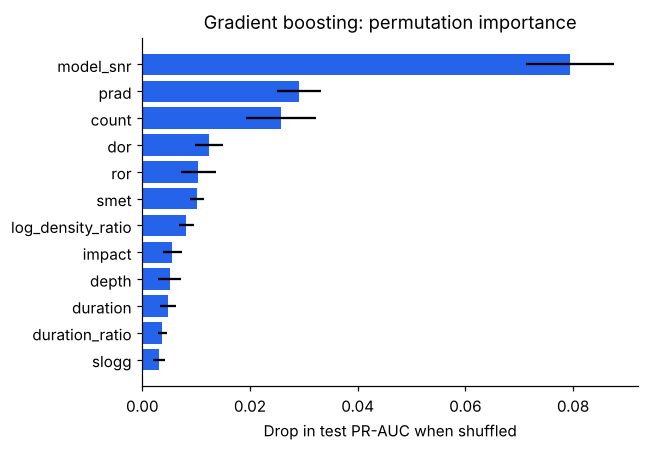

In [20]:
# (a) Logistic regression coefficients (standardized features, so magnitudes are comparable)
# CAUTION: CORE contains both raw and log versions of 8 quantities (e.g. koi_depth and log_koi_depth).
# Collinear pairs split and inflate the coefficients, so they must NOT be read as effect sizes.
lr_final = best["Logistic regression"]
coef = pd.Series(lr_final.named_steps["clf"].coef_[0], index=CORE).sort_values(key=abs, ascending=False)
print("Top logistic regression coefficients:"); print(coef.head(10).round(3))
RESULTS["lr_top_coef"] = coef.head(10).round(3).to_dict()

# (b) Permutation importance of gradient boosting on the test set (drop in PR-AUC)
hgb_final = best["Gradient boosting"]
pi = permutation_importance(hgb_final, X_te, y_te, scoring="average_precision", n_repeats=10,
                            random_state=RANDOM_STATE, n_jobs=-1)
perm = pd.Series(pi.importances_mean, index=CORE).sort_values(ascending=False)
RESULTS["perm_top"] = perm.head(10).round(4).to_dict()
fig, ax = plt.subplots(figsize=(6, 4.2))
top = perm.head(12)[::-1]
ax.barh([c.replace("koi_", "") for c in top.index], top.values, color=C_PLANET,
        xerr=pd.Series(pi.importances_std, index=CORE)[top.index].values)
ax.set_xlabel("Drop in test PR-AUC when shuffled"); ax.set_title("Gradient boosting: permutation importance")
plt.tight_layout(); plt.savefig("figures/fig_perm_importance.png"); plt.show()

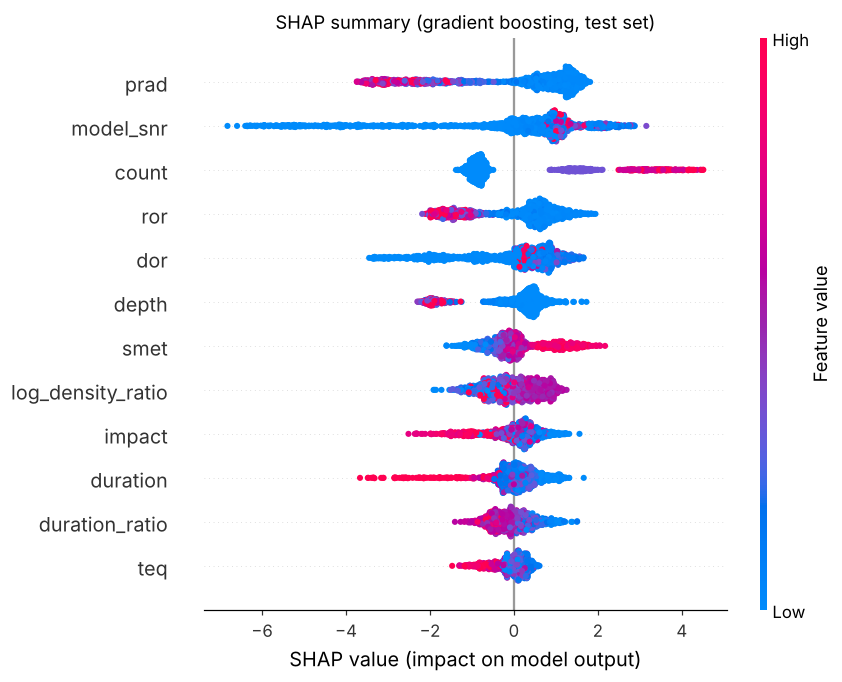

In [21]:
# (c) SHAP values for gradient boosting
try:
    import shap
    explainer = shap.TreeExplainer(hgb_final)
    sv = explainer.shap_values(X_te)
    sv = sv[1] if isinstance(sv, list) else sv
    plt.figure()
    shap.summary_plot(sv, X_te.rename(columns=lambda c: c.replace("koi_", "")), max_display=12, show=False)
    plt.title("SHAP summary (gradient boosting, test set)"); plt.tight_layout()
    plt.savefig("figures/fig_shap.png"); plt.show()
    RESULTS["shap_top"] = pd.Series(np.abs(sv).mean(0), index=CORE).sort_values(ascending=False).head(10).round(4).to_dict()
except Exception as e:
    print("SHAP unavailable:", e)

In [22]:
# (d) Feature-group ablation: cross-validated PR-AUC of gradient boosting with groups removed
groups = {"All 31 core": CORE,
          "No engineered (20 raw)": TRANSIT + STAR,
          "No host-star features": TRANSIT + ENGINEERED,
          "No transit-fit features": STAR + ENGINEERED,
          "Only engineered (11)": ENGINEERED}
abl = {}
for name, cols in groups.items():
    s = []
    for tr_i, va_i in cv.split(X_tr, y_tr, g_tr):
        m = HistGradientBoostingClassifier(**hgb_params).fit(train.iloc[tr_i][cols], y_tr[tr_i])
        s.append(average_precision_score(y_tr[va_i], m.predict_proba(train.iloc[va_i][cols])[:, 1]))
    abl[name] = {"CV PR-AUC": np.mean(s), "std": np.std(s), "n features": len(cols)}
abl = pd.DataFrame(abl).T
RESULTS["ablation"] = abl.round(4).to_dict(orient="index")
abl.round(4)

,CV PR-AUC,std,n features
All 31 core,0.9701,0.0079,31.0
No engineered (20 raw),0.9705,0.0070,20.0
No host-star features,0.9658,0.0072,25.0
No transit-fit features,0.9606,0.0112,17.0
Only engineered (11),0.9518,0.0138,11.0


**Takeaway.** SHAP and permutation importance agree on the top three features: SNR, planet radius and the number of KOIs on the star. LR coefficients are not interpretable here (collinearity). The engineered features add nothing on top of the raw ones for boosting (trees ignore log transforms) but reach 0.952 on their own.

## 11. Complexity analysis: is the extra complexity worth it?
Training time (refit on the training set), tuning time, inference time, number of learned parameters,
and saved model size, next to the test PR-AUC gain over logistic regression.

In [23]:
def n_params(name, est):
    clf = est.named_steps["clf"] if hasattr(est, "named_steps") else est
    if name == "Logistic regression":
        return int(clf.coef_.size + clf.intercept_.size)
    if name == "Neural network (MLP)":
        return int(sum(w.size for w in clf.coefs_) + sum(b.size for b in clf.intercepts_))
    return int(sum(len(p.nodes) for it in clf._predictors for p in it))   # total tree nodes

cx = {}
for name, est in best.items():
    joblib.dump(est, f"models/_tmp_{name[:3]}.joblib")
    size = os.path.getsize(f"models/_tmp_{name[:3]}.joblib") / 1024; os.remove(f"models/_tmp_{name[:3]}.joblib")
    cx[name] = {"Test PR-AUC": test_table.loc[name, "PR-AUC"],
                "Gain vs LR": test_table.loc[name, "PR-AUC"] - test_table.loc["Logistic regression", "PR-AUC"],
                "Fit time (s)": fit_time[name], "Tuning time (s)": RESULTS["tune_time_s"][name],
                "Predict (ms / 1k objects)": pred_time[name],
                "Parameters / tree nodes": n_params(name, est), "Model size (KB)": size}
cx = pd.DataFrame(cx).T
RESULTS["complexity"] = cx.round(4).to_dict(orient="index")
cx.round(3)

,Test PR-AUC,Gain vs LR,Fit time (s),Tuning time (s),Predict (ms / 1k objects),Parameters / tree nodes,Model size (KB)
Logistic regression,0.950,0.000,0.052,2.518,0.976,32.0,3.423
Gradient boosting,0.975,0.025,2.829,131.645,11.344,14018.0,905.875
Neural network (MLP),0.963,0.013,1.775,85.901,1.799,12417.0,303.970


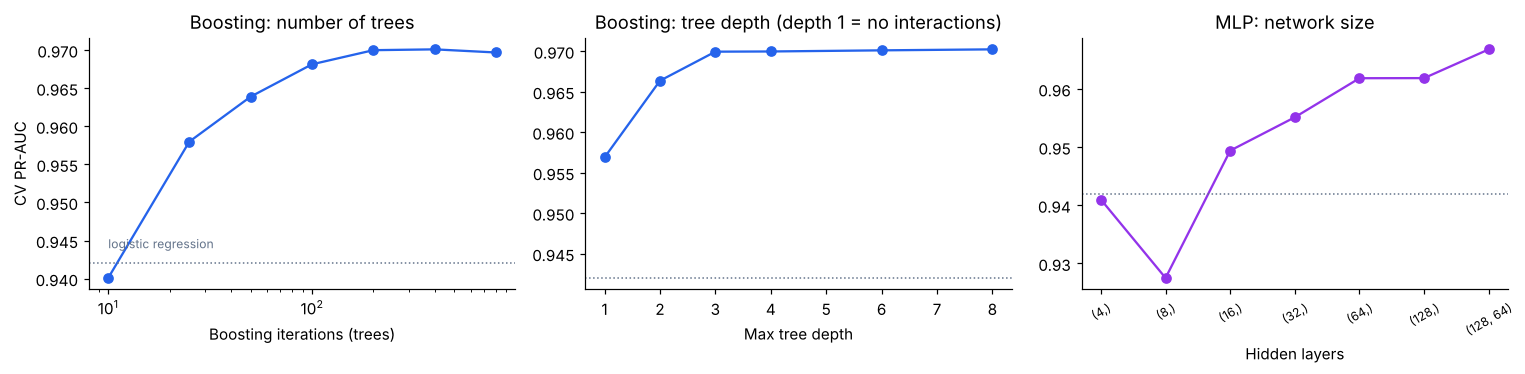

In [24]:
# Model capacity vs. validation score: boosting iterations and depth, MLP width
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
base = {k: v for k, v in hgb_params.items()}
def cv_score(est, cols=CORE):
    s = []
    for tr_i, va_i in cv.split(X_tr, y_tr, g_tr):
        e = clone(est).fit(train.iloc[tr_i][cols], y_tr[tr_i])
        s.append(average_precision_score(y_tr[va_i], e.predict_proba(train.iloc[va_i][cols])[:, 1]))
    return np.mean(s)
cap = {}
iters = [10, 25, 50, 100, 200, 400, 800]
v = [cv_score(HistGradientBoostingClassifier(**{**base, "max_iter": i})) for i in iters]
axes[0].plot(iters, v, "o-", color=MODEL_COLORS["Gradient boosting"]); axes[0].set_xscale("log")
axes[0].set_xlabel("Boosting iterations (trees)"); axes[0].set_ylabel("CV PR-AUC"); axes[0].set_title("Boosting: number of trees")
cap["iters"] = dict(zip(iters, np.round(v, 4).tolist()))
depths = [1, 2, 3, 4, 6, 8]
v = [cv_score(HistGradientBoostingClassifier(**{**base, "max_depth": d})) for d in depths]
axes[1].plot(depths, v, "o-", color=MODEL_COLORS["Gradient boosting"])
axes[1].set_xlabel("Max tree depth"); axes[1].set_title("Boosting: tree depth (depth 1 = no interactions)")
cap["depth"] = dict(zip(depths, np.round(v, 4).tolist()))
widths = [(4,), (8,), (16,), (32,), (64,), (128,), (128, 64)]
mlp_best_params = {k.replace("clf__", ""): v for k, v in mlp_search.best_params_.items() if k != "clf__hidden_layer_sizes"}
v = [cv_score(make_mlp(hidden_layer_sizes=w, **mlp_best_params)) for w in widths]
axes[2].plot(range(len(widths)), v, "o-", color=MODEL_COLORS["Neural network (MLP)"])
axes[2].set_xticks(range(len(widths))); axes[2].set_xticklabels([str(w) for w in widths], rotation=30, fontsize=8)
axes[2].set_xlabel("Hidden layers"); axes[2].set_title("MLP: network size")
cap["mlp_width"] = {str(w): s for w, s in zip(widths, np.round(v, 4).tolist())}
for ax in axes: ax.axhline(lr_search.best_score_, color=MODEL_COLORS["Logistic regression"], ls=":", lw=1)
axes[0].text(10, lr_search.best_score_ + 0.002, "logistic regression", fontsize=8, color=MODEL_COLORS["Logistic regression"])
plt.tight_layout(); plt.savefig("figures/fig_capacity.png"); plt.show()
RESULTS["capacity"] = cap

**Takeaway.** Boosting costs ~50× the tuning time and ~250× the storage of logistic regression, all still seconds and kilobytes, for +0.025 PR-AUC. Depth-1 trees already beat LR (0.957 vs. 0.942) and depth 3 adds 0.013 more, so interactions matter. The MLP needs two hidden layers just to approach boosting.

## 12. Failure analysis
We look for **where** the model stops working, not just a list of mistakes. Slices use out-of-fold (OOF)
predictions on the training set (5,800+ objects, more statistical power than the test set) from the
tuned gradient-boosting model, then we confirm the main finding on the test set.

In [25]:
fa = train.copy()
fa["p"] = oof["Gradient boosting"]; fa["pred"] = (fa["p"] >= 0.5).astype(int)
fa["error"] = (fa["pred"] != fa["label"]).astype(int)
fa["fn"] = ((fa["label"] == 1) & (fa["pred"] == 0)).astype(int)
fa["fp"] = ((fa["label"] == 0) & (fa["pred"] == 1)).astype(int)
fa_raw = labeled_full.iloc[train_idx].reset_index(drop=True)

def slice_table(col, bins, labels):
    s = pd.cut(fa[col], bins=bins, labels=labels)
    t = fa.groupby(s, observed=True).agg(n=("label", "size"), confirmed=("label", "mean"),
                                         error_rate=("error", "mean"), missed_planets=("fn", "sum"),
                                         false_alarms=("fp", "sum"))
    t["PR-AUC"] = [average_precision_score(g["label"], g["p"]) if 0 < g["label"].mean() < 1 else np.nan
                   for _, g in fa.groupby(s, observed=True)]
    return t

slices = {
 "Signal-to-noise (SNR)": slice_table("koi_model_snr", [0, 10, 15, 25, 50, 100, np.inf], ["<10", "10-15", "15-25", "25-50", "50-100", ">100"]),
 "Planet radius (Earth radii)": slice_table("koi_prad", [0, 1.25, 2, 4, 8, 15, np.inf], ["<1.25", "1.25-2", "2-4", "4-8", "8-15", ">15"]),
 "Orbital period (days)": slice_table("koi_period", [0, 3, 10, 30, 100, np.inf], ["<3", "3-10", "10-30", "30-100", ">100"]),
 "Stellar brightness (Kepler mag)": slice_table("koi_kepmag", [0, 12, 13, 14, 15, 16, np.inf], ["<12", "12-13", "13-14", "14-15", "15-16", ">16"]),
 "KOIs on the same star": slice_table("koi_count", [0, 1, 2, np.inf], ["1 (single)", "2", "3+"]),
}
for k, t in slices.items():
    print("\n==", k); print(t.round(3))
RESULTS["slices"] = {}
for k, t in slices.items():
    r = t.round(4).reset_index(); r.iloc[:, 0] = r.iloc[:, 0].astype(str); r = r.rename(columns={r.columns[0]: "bin"})
    RESULTS["slices"][k] = r.to_dict(orient="records")


== Signal-to-noise (SNR)
                  n  confirmed  error_rate  missed_planets  false_alarms  \
koi_model_snr                                                              
<10             636      0.052       0.053              22            12   
10-15           755      0.313       0.117              36            52   
15-25          1168      0.571       0.097              35            78   
25-50          1145      0.612       0.065              24            50   
50-100          610      0.531       0.054              13            20   
>100           1546      0.152       0.020              17            14   

               PR-AUC  
koi_model_snr          
<10             0.477  
10-15           0.898  
15-25           0.964  
25-50           0.980  
50-100          0.993  
>100            0.975  

== Planet radius (Earth radii)
             n  confirmed  error_rate  missed_planets  false_alarms  PR-AUC
koi_prad                                                         

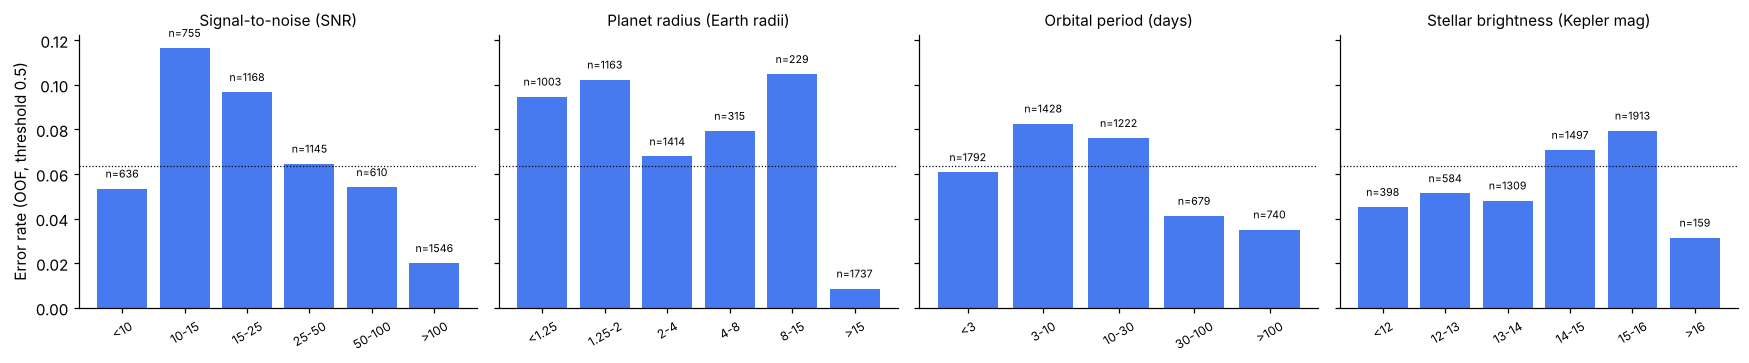

In [26]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4), sharey=True)
for ax, key in zip(axes, ["Signal-to-noise (SNR)", "Planet radius (Earth radii)", "Orbital period (days)", "Stellar brightness (Kepler mag)"]):
    t = slices[key]; x = np.arange(len(t))
    ax.bar(x, t["error_rate"], color=C_PLANET, alpha=0.85)
    for i, (e, n) in enumerate(zip(t["error_rate"], t["n"])):
        ax.text(i, e + 0.005, f"n={n}", ha="center", fontsize=7)
    ax.set_xticks(x); ax.set_xticklabels(t.index.astype(str), rotation=30, fontsize=8); ax.set_title(key, fontsize=10)
    ax.axhline(fa["error"].mean(), color="k", ls=":", lw=0.8)
axes[0].set_ylabel("Error rate (OOF, threshold 0.5)")
plt.tight_layout(); plt.savefig("figures/fig_failure_slices.png"); plt.show()
RESULTS["oof_error_rate"] = float(fa["error"].mean())

In [27]:
# Anomaly detection (course topic): are errors concentrated on unusual host stars?
star_cols = ["koi_steff", "koi_slogg", "koi_srad", "koi_smass", "koi_smet"]
star_X = SimpleImputer(strategy="median").fit(X_tr[star_cols]).transform(X_tr[star_cols])
iso = IsolationForest(contamination=0.05, random_state=RANDOM_STATE).fit(star_X)
fa["unusual_star"] = (iso.predict(star_X) == -1).astype(int)
# Missing measurements
fa["any_missing"] = X_tr.isna().any(axis=1).astype(int)
extra = {}
for col, name in [("unusual_star", "Unusual host star (IsolationForest, top 5%)"), ("any_missing", "Any core feature missing")]:
    g = fa.groupby(col).agg(n=("label", "size"), confirmed=("label", "mean"), error_rate=("error", "mean"))
    print("\n==", name); print(g.round(3)); extra[name] = g.round(4).to_dict(orient="index")
# Confident mistakes
fa["confident_wrong"] = (((fa["p"] > 0.9) & (fa["label"] == 0)) | ((fa["p"] < 0.1) & (fa["label"] == 1))).astype(int)
print("\nConfident mistakes (p>0.9 on FP or p<0.1 on planet):", fa["confident_wrong"].sum(), "of", fa["error"].sum(), "errors")
extra["confident_wrong"] = [int(fa["confident_wrong"].sum()), int(fa["error"].sum())]
RESULTS["failure_extra"] = extra


== Unusual host star (IsolationForest, top 5%)
                 n  confirmed  error_rate
unusual_star                             
0             5568      0.389       0.065
1              293      0.106       0.034

== Any core feature missing
                n  confirmed  error_rate
any_missing                             
0            5839      0.376       0.064
1              22      0.000       0.045

Confident mistakes (p>0.9 on FP or p<0.1 on planet): 138 of 374 errors


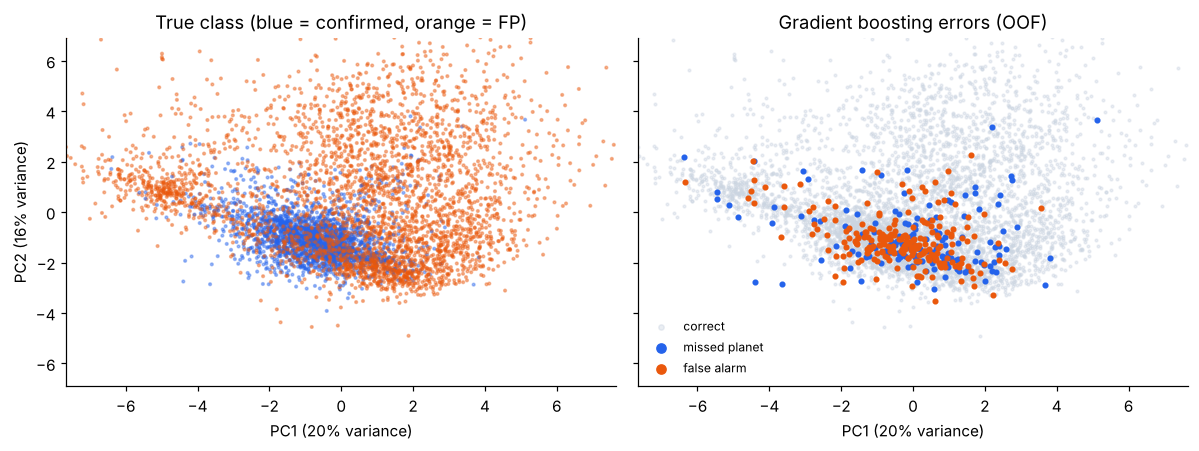

In [28]:
# Where are the errors in feature space? PCA of the standardized core features
Z = Pipeline([("i", SimpleImputer(strategy="median")), ("s", StandardScaler()), ("p", PCA(2, random_state=RANDOM_STATE))]).fit(X_tr)
pc = Z.transform(X_tr); ev = Z.named_steps["p"].explained_variance_ratio_
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True, sharey=True)
lim = np.percentile(np.abs(pc), 99, axis=0)
axes[0].scatter(pc[:, 0], pc[:, 1], c=np.where(y_tr == 1, C_PLANET, C_FP), s=3, alpha=0.4)
axes[0].set_title("True class (blue = confirmed, orange = FP)")
ok = fa["error"].values == 0
axes[1].scatter(pc[ok, 0], pc[ok, 1], c="#cbd5e1", s=3, alpha=0.4, label="correct")
axes[1].scatter(pc[fa.fn == 1, 0], pc[fa.fn == 1, 1], c=C_PLANET, s=9, label="missed planet")
axes[1].scatter(pc[fa.fp == 1, 0], pc[fa.fp == 1, 1], c=C_FP, s=9, label="false alarm")
axes[1].set_title("Gradient boosting errors (OOF)"); axes[1].legend(frameon=False, fontsize=8, markerscale=2)
for ax in axes:
    ax.set_xlim(-lim[0] * 1.1, lim[0] * 1.1); ax.set_ylim(-lim[1] * 1.1, lim[1] * 1.1)
    ax.set_xlabel(f"PC1 ({ev[0]:.0%} variance)")
axes[0].set_ylabel(f"PC2 ({ev[1]:.0%} variance)")
plt.tight_layout(); plt.savefig("figures/fig_pca_errors.png"); plt.show()
RESULTS["pca_var"] = ev.round(3).tolist()

In [29]:
# Manual review: the most confident mistakes, with Kepler's vetting comment (used ONLY for post-hoc review)
review = fa.assign(comment=fa_raw["koi_comment"].values, fpflags=fa_raw[["koi_fpflag_nt", "koi_fpflag_ss",
                   "koi_fpflag_co", "koi_fpflag_ec"]].astype(str).agg("".join, axis=1).values)
cols = ["kepoi_name", "label", "p", "koi_model_snr", "koi_prad", "koi_period", "log_density_ratio", "koi_count", "fpflags", "comment"]
worst_fp = review[review.fp == 1].sort_values("p", ascending=False)[cols].head(10)
worst_fn = review[review.fn == 1].sort_values("p")[cols].head(10)
print("Most confident false alarms (FP predicted as planet):"); display(worst_fp.round(3))
print("Most confident missed planets:"); display(worst_fn.round(3))
# Which vetting flag do the false alarms carry? (nt=not transit-like, ss=stellar eclipse, co=centroid offset, ec=ephemeris match)
fa_fp = review[review.fp == 1]
flag_share = {f: float(fa_raw.loc[fa.fp == 1, "koi_fpflag_" + f].mean()) for f in ["nt", "ss", "co", "ec"]}
flag_share_all = {f: float(fa_raw.loc[fa.label == 0, "koi_fpflag_" + f].mean()) for f in ["nt", "ss", "co", "ec"]}
print("Share of false alarms carrying each flag:", {k: round(v, 3) for k, v in flag_share.items()})
print("Share of ALL false positives carrying each flag:", {k: round(v, 3) for k, v in flag_share_all.items()})
RESULTS["flag_share_false_alarms"] = flag_share; RESULTS["flag_share_all_fp"] = flag_share_all
RESULTS["worst_fp"] = worst_fp.drop(columns="comment").round(3).to_dict(orient="records")
RESULTS["worst_fn"] = worst_fn.drop(columns="comment").round(3).to_dict(orient="records")

Most confident false alarms (FP predicted as planet):


,kepoi_name,label,p,koi_model_snr,koi_prad,koi_period,log_density_ratio,koi_count,fpflags,comment
3800,K02570.01,0,1.000,21.9,1.81,79.920,-0.175,2,0010,CENT_UNRESOLVED_OFFSET
3914,K02050.01,0,1.000,30.1,1.60,75.379,0.386,2,0111,MOD_SEC_DV---DEEP_V_SHAPED---HAS_SEC_TCE---CEN...
3258,K01803.02,0,1.000,12.7,1.37,12.720,-0.224,3,0001,CENT_KIC_POS---EPHEM_MATCH
1391,K02159.02,0,0.999,20.5,1.33,2.393,-0.168,2,0010,CENT_UNRESOLVED_OFFSET
4616,K00989.04,0,0.999,43.1,2.92,4.080,-0.122,4,0010,CLEAR_APO
357,K01196.01,0,0.999,27.1,3.32,3.982,0.270,3,0011,CENT_RESOLVED_OFFSET---HALO_GHOST---EPHEM_MATCH
3750,K01953.01,0,0.999,26.1,2.09,15.160,-0.142,1,0010,CENT_RESOLVED_OFFSET---HALO_GHOST
1713,K02713.01,0,0.999,25.1,1.72,21.391,0.049,1,0110,MOD_SEC_DV---MOD_SEC_ALT---HAS_SEC_TCE---CENT_...
3829,K01712.01,0,0.999,36.8,2.72,10.161,0.304,1,0001,CENT_KIC_POS---EPHEM_MATCH
2557,K00724.01,0,0.999,41.7,2.07,6.971,-0.195,1,0010,CENT_UNRESOLVED_OFFSET---HALO_GHOST


Most confident missed planets:


,kepoi_name,label,p,koi_model_snr,koi_prad,koi_period,log_density_ratio,koi_count,fpflags,comment
574,K01450.01,1,0.000,334.8,59.19,2.145,-1.164,1,0100,HAS_SEC_TCE
3671,K03794.01,1,0.000,217.4,22.95,0.654,-1.000,1,0000,NO_COMMENT
3709,K03728.01,1,0.000,56.4,22.27,5.546,0.927,1,0000,HAS_SEC_TCE
2941,K04706.01,1,0.001,10.3,1.31,101.952,0.520,1,0000,NO_COMMENT
4488,K03503.02,1,0.001,7.7,0.80,31.825,-0.144,2,0000,KIC_OFFSET
2580,K04072.01,1,0.001,20.9,2.24,0.693,0.330,1,0000,NO_COMMENT
3242,K03503.01,1,0.002,8.5,0.79,21.188,-0.353,2,0000,NO_COMMENT
133,K00846.01,1,0.002,748.1,13.84,27.808,-0.105,1,0000,NO_COMMENT
2621,K04024.01,1,0.002,6.8,1.95,8.407,1.507,1,0000,NO_COMMENT
2681,K04053.01,1,0.002,8.1,0.85,1.420,0.202,1,0000,NO_COMMENT


Share of false alarms carrying each flag: {'nt': 0.11, 'ss': 0.379, 'co': 0.727, 'ec': 0.335}
Share of ALL false positives carrying each flag: {'nt': 0.294, 'ss': 0.478, 'co': 0.405, 'ec': 0.246}


**Is the model least confident where it fails?** Mean distance of the OOF probability from 0.5 (higher = more confident), by slice.

In [30]:
conf = (fa["p"] - 0.5).abs()
conf_snr = conf.groupby(pd.cut(fa["koi_model_snr"], [0, 10, 15, 25, 50, 100, np.inf]), observed=True).mean()
conf_cnt = conf.groupby(pd.cut(fa["koi_count"], [0, 1, 2, np.inf], labels=["1", "2", "3+"]), observed=True).mean()
print("Mean |p - 0.5| by SNR:"); print(conf_snr.round(3))
print("\nMean |p - 0.5| by KOIs on the same star:"); print(conf_cnt.round(3))
RESULTS["conf_by_snr"] = {str(k): float(v) for k, v in conf_snr.round(4).items()}
RESULTS["conf_by_count"] = {str(k): float(v) for k, v in conf_cnt.round(4).items()}

Mean |p - 0.5| by SNR:
koi_model_snr
(0.0, 10.0]      0.471
(10.0, 15.0]     0.435
(15.0, 25.0]     0.445
(25.0, 50.0]     0.461
(50.0, 100.0]    0.471
(100.0, inf]     0.485
Name: p, dtype: float64

Mean |p - 0.5| by KOIs on the same star:
koi_count
1     0.461
2     0.461
3+    0.482
Name: p, dtype: float64


**Takeaway.** Errors concentrate at SNR 10–15 (11.7% error) and the model cannot rank below SNR 10 (PR-AUC 0.48), even though it is confident there (most objects are clear false positives). Lowest confidence is at SNR 10–25. 73% of false alarms carry the centroid-offset flag (vs. 40% of all false positives): blended light. Unusual host stars are not a failure mode.

## 13. Mitigations for the main failure modes
*Evaluated on the test set as post-hoc checks of the chosen model.*
1. **Unreliable confidence** → isotonic recalibration (Section 9).
2. **Errors concentrated where the model is unsure** → *selective prediction*: the model abstains on objects
   with calibrated probability in an uncertain band and sends them to human vetting. We measure accuracy vs. coverage.
3. **False alarms caused by centroid offsets (blended light from a nearby star)** → the centroid diagnostics
   (`koi_fwm_stat_sig`, `koi_dicco_msky`, `koi_dikco_msky`) are pre-vetting measurements that directly target this failure.
   We test adding only these three to the core set.

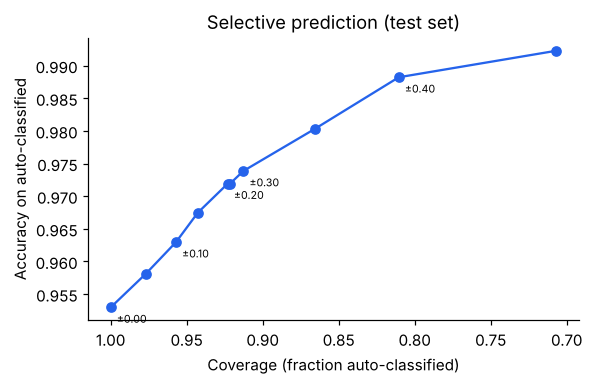

,band half-width,coverage,accuracy on kept,objects sent to humans
0,0.00,1.000,0.953,0
1,0.05,0.977,0.958,34
2,0.10,0.957,0.963,63
3,0.15,0.943,0.967,84
4,0.20,0.923,0.972,113
5,0.25,0.922,0.972,115
6,0.30,0.913,0.974,128
7,0.35,0.866,0.980,197
8,0.40,0.810,0.988,278
9,0.45,0.707,0.992,430


In [31]:
# Mitigation 2: selective prediction on the test set (calibrated gradient boosting)
p_cal = cal_probs["Gradient boosting"]
sel = []
for w in np.arange(0, 0.46, 0.05):
    keep_ = (p_cal <= 0.5 - w) | (p_cal >= 0.5 + w)
    if keep_.sum() == 0: continue
    acc = accuracy_score(y_te[keep_], (p_cal[keep_] >= 0.5).astype(int))
    sel.append({"band half-width": round(w, 2), "coverage": keep_.mean(), "accuracy on kept": acc,
                "objects sent to humans": int((~keep_).sum())})
sel = pd.DataFrame(sel); RESULTS["selective"] = sel.round(4).to_dict(orient="records")
fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.plot(sel["coverage"], sel["accuracy on kept"], "o-", color=C_PLANET)
for _, r in sel.iloc[::2].iterrows():
    ax.annotate(f"±{r['band half-width']:.2f}", (r["coverage"], r["accuracy on kept"]), fontsize=7,
                xytext=(4, -10), textcoords="offset points")
ax.set_xlabel("Coverage (fraction auto-classified)"); ax.set_ylabel("Accuracy on auto-classified")
ax.set_title("Selective prediction (test set)"); ax.invert_xaxis()
plt.tight_layout(); plt.savefig("figures/fig_selective.png"); plt.show()
sel.round(3)

In [32]:
# Mitigation 3: add only the centroid diagnostics, which target the blended-light failure mode
CENTROID = ["koi_fwm_stat_sig", "koi_dicco_msky", "koi_dikco_msky"]
m3 = HistGradientBoostingClassifier(**hgb_params).fit(lab_tr[CORE + CENTROID], y_tr)
p3 = m3.predict_proba(lab_te[CORE + CENTROID])[:, 1]
base_p = test_probs["Gradient boosting"]
co_te = lab_te["koi_fpflag_co"].values == 1
mit = pd.DataFrame({
  "Core (31)": {**metrics(y_te, base_p), "false alarms among centroid-offset FPs": int(((base_p >= .5) & co_te).sum())},
  "Core + 3 centroid diagnostics": {**metrics(y_te, p3), "false alarms among centroid-offset FPs": int(((p3 >= .5) & co_te).sum())}}).T
print("Centroid-offset false positives in the test set:", int(co_te.sum()))
RESULTS["mitigation_centroid"] = mit.round(4).to_dict(orient="index"); RESULTS["n_co_test"] = int(co_te.sum())
mit.round(3)

Centroid-offset false positives in the test set: 392


,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy,Brier,false alarms among centroid-offset FPs
Core (31),0.975,0.987,0.921,0.958,0.939,0.954,0.040,33.0
Core + 3 centroid diagnostics,0.997,0.998,0.969,0.976,0.973,0.980,0.016,2.0


**Is the centroid gain just missingness?** The centroid measures are missing more often for false positives. To check that the
model is not simply learning "missing = false positive", we median-impute them (so missingness carries no signal) and also score
only the test objects where all three are present.

In [33]:
imp_c = SimpleImputer(strategy="median").fit(lab_tr[CENTROID])
add_imp = lambda d: pd.concat([d[CORE], pd.DataFrame(imp_c.transform(d[CENTROID]), columns=CENTROID, index=d.index)], axis=1)
p3_imp = HistGradientBoostingClassifier(**hgb_params).fit(add_imp(lab_tr), y_tr).predict_proba(add_imp(lab_te))[:, 1]
present = lab_te[CENTROID].notna().all(axis=1).values
cen_chk = pd.DataFrame({
    "PR-AUC (all test)": [average_precision_score(y_te, p) for p in (base_p, p3, p3_imp)],
    "PR-AUC (centroids present)": [average_precision_score(y_te[present], p[present]) for p in (base_p, p3, p3_imp)],
    "false alarms among centroid-offset FPs": [int(((p >= .5) & co_te).sum()) for p in (base_p, p3, p3_imp)]},
    index=["Core (31)", "+ centroid (missing kept)", "+ centroid (median-imputed)"])
print("Test objects with all three centroid measures present:", int(present.sum()), "of", len(present))
RESULTS["centroid_missingness_check"] = cen_chk.round(4).to_dict(orient="index")
cen_chk.round(3)

Test objects with all three centroid measures present: 1266 of 1467


,PR-AUC (all test),PR-AUC (centroids present),false alarms among centroid-offset FPs
Core (31),0.975,0.981,33
+ centroid (missing kept),0.997,0.998,2
+ centroid (median-imputed),0.997,0.998,3


**Takeaway.** Abstaining within ±0.2 of 0.5 sends 7.7% of objects to humans and raises accuracy from 95.3% to 97.2%. The centroid gain survives median imputation, so it is real information, not missingness; it remains an optional variant because the vetting rules threshold these same measures (and the false-alarm count is graded with the flag those rules produce).

## 14. Final model and candidate ranking
Final model: the configuration chosen in the conclusions (see report), refit on **all** labeled objects,
with isotonic recalibration learned from grouped out-of-fold predictions. It ranks 1,873 of the 1,977 unresolved
CANDIDATE objects (the other 104 have no transit fit and cannot be scored) for follow-up. Scores are prioritization aids, not confirmations.

In [34]:
FINAL_NAME = "Gradient boosting"
X_all, y_all, g_all = data[CORE], data["label"].values, data["kepid"].values
final_est = clone(best[FINAL_NAME]).fit(X_all, y_all)
oof_all = cross_val_predict(clone(best[FINAL_NAME]), X_all, y_all, groups=g_all, cv=cv,
                            method="predict_proba", n_jobs=-1)[:, 1]
final_cal = IsotonicRegression(out_of_bounds="clip").fit(oof_all, y_all)
bundle = {"model": final_est, "calibrator": final_cal, "features": CORE,
          "description": "HistGradientBoosting on 31 core KOI features + isotonic calibration. "
                         "Use: p = calibrator.predict(model.predict_proba(X[features])[:,1])"}
joblib.dump(bundle, "models/final_model.joblib")
print("Saved models/final_model.joblib", round(os.path.getsize("models/final_model.joblib") / 1024, 1), "KB")

cand_raw = final_est.predict_proba(candidates[CORE])[:, 1]
cand_p = final_cal.predict(cand_raw)
ranked = cand_full[["kepoi_name", "kepid", "koi_period", "koi_prad", "koi_model_snr", "koi_count", "koi_score"]].copy()
ranked["planet_probability"] = cand_p          # calibrated (isotonic has flat steps, so ties are possible)
ranked["raw_score"] = cand_raw                 # used to break ties in the ranking
ranked = ranked.sort_values(["planet_probability", "raw_score"], ascending=False).reset_index(drop=True)
ranked.to_csv("results/candidate_ranking.csv", index=False)
rho = spearmanr(ranked["planet_probability"], ranked["koi_score"], nan_policy="omit")[0]
print(f"Candidates with p >= 0.9: {(cand_p >= 0.9).sum()} | p <= 0.1: {(cand_p <= 0.1).sum()}")
print(f"Spearman correlation with Kepler's koi_score (not used in training): {rho:.3f}")
top = ranked[ranked.planet_probability >= 0.9]
RESULTS["cand_top_multi_share"] = float((top.koi_count > 1).mean()); RESULTS["cand_top_median_prad"] = float(top.koi_prad.median())
RESULTS["cand_disagree"] = int(((ranked.planet_probability >= 0.9) & (ranked.koi_score < 0.1)).sum())
RESULTS["candidates"] = {"p_ge_09": int((cand_p >= 0.9).sum()), "p_le_01": int((cand_p <= 0.1).sum()),
                         "p_mid": int(((cand_p > 0.1) & (cand_p < 0.9)).sum()), "spearman_koi_score": float(rho),
                         "top10": ranked.head(10).round(3).to_dict(orient="records")}
ranked.head(10).round(3)

Saved models/final_model.joblib 913.8 KB
Candidates with p >= 0.9: 192 | p <= 0.1: 804
Spearman correlation with Kepler's koi_score (not used in training): 0.279


,kepoi_name,kepid,koi_period,koi_prad,koi_model_snr,koi_count,koi_score,planet_probability,raw_score
0,K01590.01,5542466,12.890,1.93,23.6,3,0.998,1.000,1.0
1,K01590.03,5542466,4.747,1.30,12.5,3,0.996,0.995,1.0
2,K03936.01,4947556,141.609,2.98,43.3,2,0.000,0.995,1.0
3,K01053.02,5956656,46.245,2.46,15.5,2,0.908,0.995,1.0
4,K00750.02,10662202,5.044,1.18,10.2,4,0.915,0.995,1.0
5,K01628.03,6975129,37.840,1.76,23.7,3,0.000,0.995,1.0
6,K04526.01,3765917,30.539,2.72,15.0,2,0.924,0.995,1.0
7,K01338.02,4466677,42.037,1.66,14.7,3,0.999,0.995,1.0
8,K01194.02,3554031,14.862,1.57,14.4,3,0.000,0.995,1.0
9,K02037.03,9634821,8.563,2.26,15.2,3,1.000,0.995,1.0


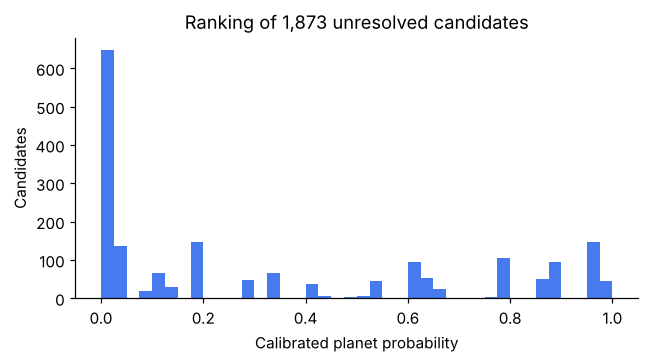

Saved results/results.json


In [35]:
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.hist(cand_p, bins=40, color=C_PLANET, alpha=0.85)
ax.set_xlabel("Calibrated planet probability"); ax.set_ylabel("Candidates")
ax.set_title(f"Ranking of {len(cand_p):,} unresolved candidates")
plt.tight_layout(); plt.savefig("figures/fig_candidates.png"); plt.show()

with open("results/results.json", "w") as f:
    json.dump(RESULTS, f, indent=1, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("Saved results/results.json")

**Takeaway.** 192 candidates score ≥ 0.9 and 804 score ≤ 0.1. The ranking correlates only 0.28 with Kepler's `koi_score`, so it adds a different view; the 6 candidates where the two strongly disagree deserve a second look.

## 15. Summary
* **Main result:** gradient boosting on 31 pre-vetting features reaches test PR-AUC 0.975 (LR 0.950, MLP 0.963), matching Kepler's own `koi_score`.
* **LR → boosting is worth it:** robust on all 5 splits, halves false alarms, costs seconds and kilobytes. **Boosting → MLP is not:** slightly worse, data-hungry, harder to explain.
* **Data decisions mattered most:** leakage removal, grouping by star, and holding back the pipeline diagnostics.
* **Failures:** weak signals, small and isolated planets, blended light, giants with wrong stellar parameters. Mitigations: recalibration, abstention, optional centroid variant.
* **Test-set use:** no tuning or model choice used the test set; Sections 7, 10 and 13 are post-hoc analyses on it.

All numbers are saved in `results/results.json`. See the report for the full discussion.